# 01 — Digital Images: Pixels, Arrays, and Representation

A digital image is both a sampled signal and a numerical array. This laboratory establishes the representation conventions needed before manipulating contrast, filtering, or preparing data for Computer Vision.

## Learning objectives
- Relate pixels to samples of a spatial signal and identify image dimensions.
- Inspect grayscale and RGB array shapes, channel order, dtype, and intensity range.
- Calculate raw memory requirements and distinguish views from copies.
- Predict uint8 overflow and perform safe intensity arithmetic.
- Interpret cropping, magnification, and quantization without confusing display size with information content.

Run all cells in order in the existing Python environment. The original experiment and its saved outputs are preserved below. Supplementary experiments use only the bundled `skimage.data.astronaut()` and `skimage.data.camera()` arrays; no external images are needed.

## 1. Mathematical foundations

A continuous scene measurement $f(x,y)$ becomes a sampled image after spatial sampling and intensity quantization:

$$I[i,j]=Q\bigl(f(j\Delta_x,i\Delta_y)\bigr),\quad 0\leq i<H,\quad 0\leq j<W.$$

Here $i$ indexes rows (vertical position), $j$ indexes columns (horizontal position), and $Q$ maps measured values to discrete codes. In an actual camera, each pixel integrates light over an area and exposure time; a point sample is a useful idealization. Sampling limits spatial detail, whereas quantization limits intensity precision.

A grayscale uint8 image has shape $(H,W)$ and values in $\{0,\ldots,255\}$. An RGB image has shape $(H,W,3)$, where the last axis stores red, green, and blue **in that order** for our sample. Eight bits provide $2^8=256$ possible codes per channel; code 255 is not a calibrated measurement of scene radiance.

For an array with $C$ channels and $b$ bytes per element, raw element storage is

$$M=HWCb\ \text{bytes}.$$

For grayscale, take $C=1$. This excludes Python object overhead and is unrelated to the compressed size of a PNG or JPEG file. Float64 uses 8 bytes per element; uint8 uses 1. Normalization is a representation change,

$$x=I/255\in[0,1],$$

not an increase in the information captured by the camera.

## 2. Original experiment — load and inspect two image arrays

The following code and saved outputs are unchanged. Check that `shape` reports height before width and that RGB has an additional channel axis. Both images happen to be square; supplementary indexing examples make the axis conventions more explicit. `vmin=0, vmax=255` fixes the grayscale display scale.

Astronaut shape: (512, 512, 3)
Astronaut dtype: uint8
Camera shape: (512, 512)
Camera dtype: uint8


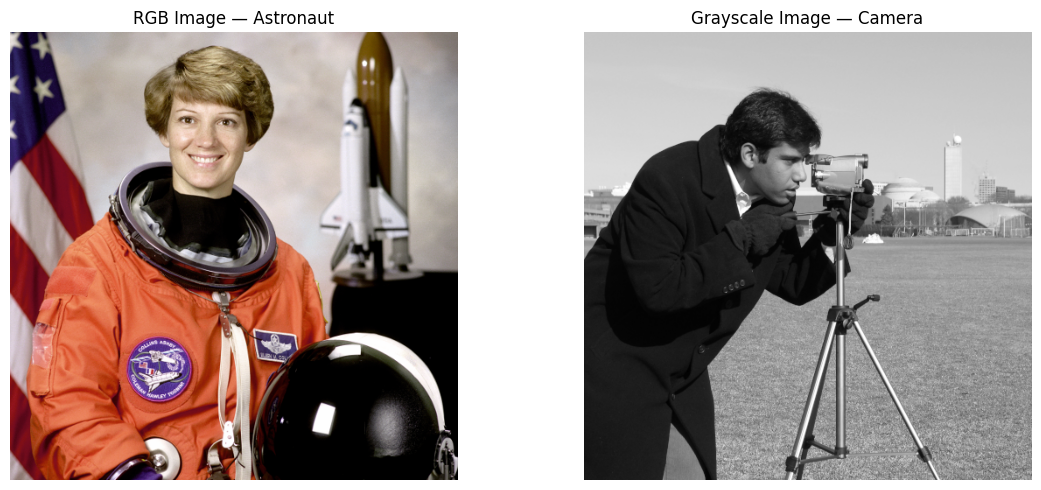

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load built-in sample images
astronaut = data.astronaut()
camera = data.camera()

print("Astronaut shape:", astronaut.shape)
print("Astronaut dtype:", astronaut.dtype)

print("Camera shape:", camera.shape)
print("Camera dtype:", camera.dtype)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(astronaut)
axes[0].set_title("RGB Image — Astronaut")

axes[1].imshow(camera, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale Image — Camera")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Interpretation of the original result

`astronaut` contains three uint8 values per spatial location; `camera` contains one. Neither the larger Matplotlib display nor an RGB channel count changes the number of spatial sample locations. In a display, the horizontal axis corresponds to columns, while the vertical axis corresponds to rows; `imshow` places row zero at the top by default.

## 3. Supplementary experiment — coordinates, crops, and memory

Use indexing `image[row, column, channel]` for RGB and `image[row, column]` for grayscale. Slicing with `start:stop` includes `start` and excludes `stop`. A basic NumPy slice usually shares the original buffer; `.copy()` creates independent storage. Inspect sharing without modifying the original image.

For a contiguous C-order RGB array, the byte strides are $(WCb,Cb,b)$. Sliced arrays may have different strides and need not be contiguous, even though their visible pixels are well defined.

RGB at (row, column): (200, 240) [5 3 2]
RGB shape (H, W, C): (512, 512, 3) | byte strides: (1536, 3, 1)
RGB raw storage: 786432 bytes
Grayscale raw storage: 262144 bytes
RGB float64 raw storage: 6291456 bytes
Crop shape: (130, 120, 3) | contiguous: False
Slice shares memory: True
Copy shares memory: False


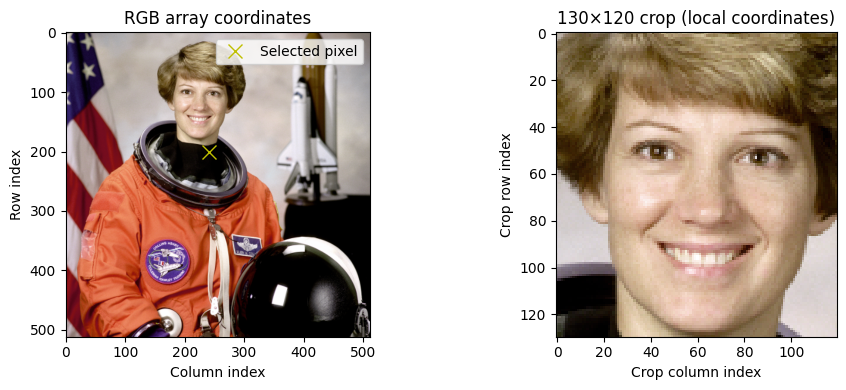

In [2]:
height, width, channels = astronaut.shape
expected_bytes = height * width * channels * astronaut.dtype.itemsize
assert astronaut.nbytes == expected_bytes
assert camera.nbytes == camera.shape[0] * camera.shape[1] * camera.dtype.itemsize

row, column = 200, 240
print('RGB at (row, column):', (row, column), astronaut[row, column])
print('RGB shape (H, W, C):', astronaut.shape, '| byte strides:', astronaut.strides)
print('RGB raw storage:', astronaut.nbytes, 'bytes')
print('Grayscale raw storage:', camera.nbytes, 'bytes')
print('RGB float64 raw storage:', astronaut.astype(np.float64).nbytes, 'bytes')

face_crop = astronaut[50:180, 160:280]
independent_crop = face_crop.copy()
print('Crop shape:', face_crop.shape, '| contiguous:', face_crop.flags.c_contiguous)
print('Slice shares memory:', np.shares_memory(face_crop, astronaut))
print('Copy shares memory:', np.shares_memory(independent_crop, astronaut))
assert face_crop.shape == (130, 120, 3)
assert np.shares_memory(face_crop, astronaut)
assert not np.shares_memory(independent_crop, astronaut)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(astronaut)
axes[0].plot(column, row, 'yx', markersize=10, label='Selected pixel')
axes[0].set(xlabel='Column index', ylabel='Row index', title='RGB array coordinates')
axes[0].legend()
axes[1].imshow(face_crop, interpolation='nearest')
axes[1].set(xlabel='Crop column index', ylabel='Crop row index', title='130×120 crop (local coordinates)')
plt.tight_layout()
plt.show()

## 4. Supplementary experiment — dtype and safe arithmetic

Unsigned 8-bit arithmetic can wrap modulo 256: $250+20$ becomes $14$ if the addition stays in uint8. A safe brightness adjustment converts to a wider dtype first, adds the offset, clips to $[0,255]$, and only then converts back.

For normalized floats, Matplotlib expects RGB values in $[0,1]$; for uint8 RGB it expects $[0,255]$. Grayscale autoscaling can hide brightness differences, so keep explicit shared display limits.

Input: [  0 100 250 255]
Wrapped uint8 + 20: [ 20 120  14  19]
Clipped wider-dtype + 20: [ 20 120 255 255]
Fraction saturated at 255 after safe brightening: 0.1616058349609375


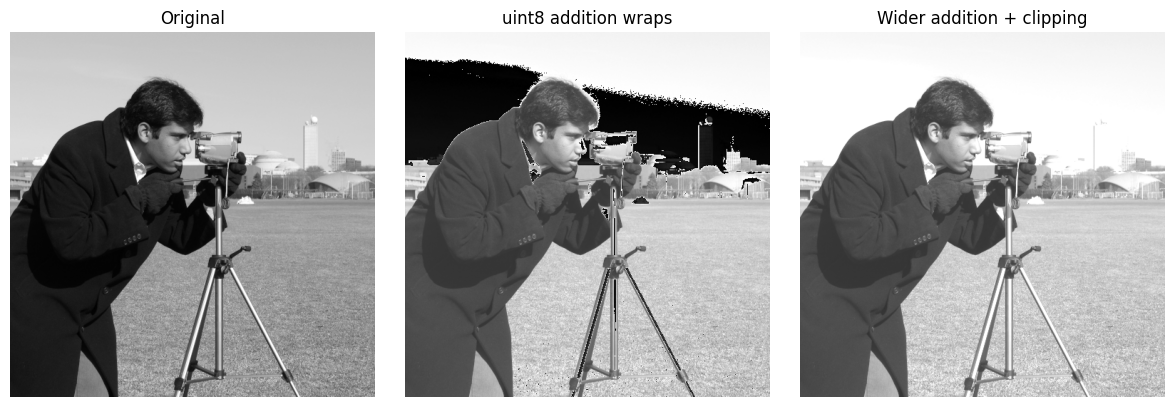

In [3]:
example = np.array([0, 100, 250, 255], dtype=np.uint8)
wrapped_example = example + np.uint8(20)
safe_example = np.clip(example.astype(np.int16) + 20, 0, 255).astype(np.uint8)
print('Input:', example)
print('Wrapped uint8 + 20:', wrapped_example)
print('Clipped wider-dtype + 20:', safe_example)
assert wrapped_example[2] == 14 and safe_example[2] == 255

normalized = camera.astype(np.float64) / 255.0
roundtrip = np.clip(np.rint(normalized * 255), 0, 255).astype(np.uint8)
assert np.array_equal(roundtrip, camera)
assert normalized.dtype == np.float64 and 0 <= normalized.min() <= normalized.max() <= 1
wrapped = camera + np.uint8(50)
brightened = np.clip(camera.astype(np.int16) + 50, 0, 255).astype(np.uint8)
print('Fraction saturated at 255 after safe brightening:', np.mean(brightened == 255))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, arr, title in zip(axes, [camera, wrapped, brightened],
                         ['Original', 'uint8 addition wraps', 'Wider addition + clipping']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Supplementary experiment — intensity quantization versus display magnification

Reduce 256 intensity levels to $L$ reconstruction levels using a normalized quantizer:

$$q_L(x)=\frac{\operatorname{round}((L-1)x)}{L-1},\quad L\geq2.$$

This keeps spatial dimensions fixed while reducing intensity precision. In contrast, displaying a small patch at a larger size makes existing pixels easier to see; it creates no new samples. The quantization RMSE measures coding error in normalized intensity units, not perceptual quality.

256 levels | normalized RMSE: 0.000000
 16 levels | normalized RMSE: 0.020220
  4 levels | normalized RMSE: 0.105554


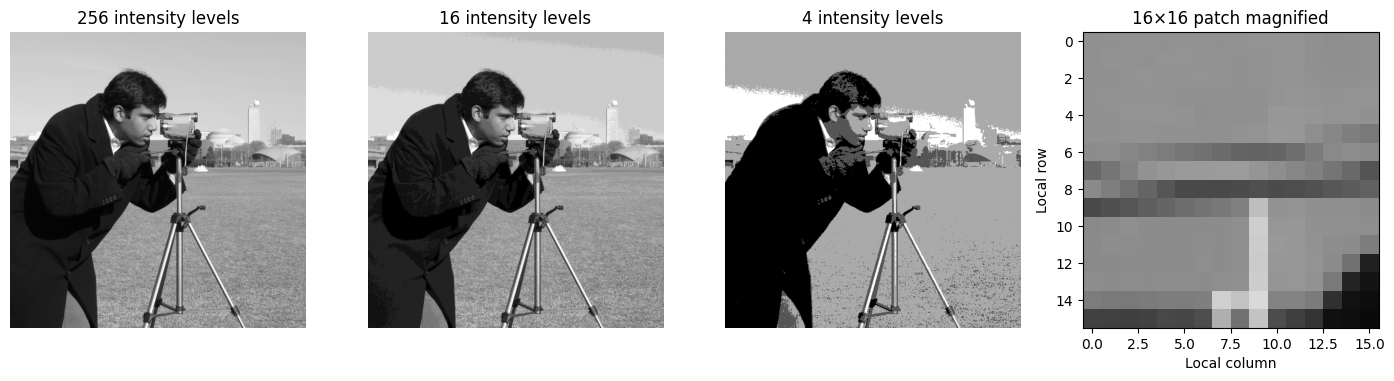

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, levels in zip(axes[:3], [256, 16, 4]):
    quantized = np.rint(normalized * (levels - 1)) / (levels - 1)
    rmse = np.sqrt(np.mean((quantized - normalized) ** 2))
    assert quantized.shape == camera.shape and len(np.unique(quantized)) <= levels
    print(f'{levels:3d} levels | normalized RMSE: {rmse:.6f}')
    ax.imshow(quantized, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{levels} intensity levels')
    ax.axis('off')
patch = camera[200:216, 250:266]
axes[3].imshow(patch, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
axes[3].set_title('16×16 patch magnified')
axes[3].set(xlabel='Local column', ylabel='Local row')
plt.tight_layout()
plt.show()

## Interpretation, limitations, and review questions

The crop changes array dimensions but preserves the selected sample values. The dtype experiment shows why numerical representation is part of an algorithm: unintended wraparound can radically alter an image. Converting to floats improves arithmetic precision but does not recover values lost through clipping, quantization, or camera saturation. Coarse quantization creates visible intensity steps even though the pixel grid is unchanged.

These display images are not calibrated sensor measurements. Their RGB values depend on color encoding and prior processing; later notebooks distinguish encoded luma from linear-light luminance. `nbytes` reports logical element storage and does not mean a slice owns a separate allocation. A simple subsample without antialiasing can also create false spatial patterns; proper resampling is a separate filtering problem.

1. How many raw bytes does a 480×640 RGB uint8 array require? What changes for float64?
2. Why is `image[10, 20]` the pixel at column 20, row 10?
3. What happens if a basic slice is modified in place? How would you isolate the change?
4. Why can dividing by 255 and rounding back preserve uint8 values, while clipping cannot preserve them all?
5. How do spatial sampling, intensity quantization, and display magnification differ?
6. Why should normalized float RGB and uint8 RGB use different numeric ranges?

## Conclusion and connection

Digital images are sampled signals stored in arrays with explicit shape, axis order, dtype, and memory layout. These conventions govern every later experiment. Computer Vision uses those arrays as measurements, Signal Processing explains sampling and quantization, and Deep Learning adds batch and channel-layout conventions. Correct numerical representation is the foundation for meaningful image transformations.